## Validacion Cruzada (Cross-Validation)

Es una técnica de evaluación en Aprendizaje Automático para **estimar qué tan bien generalizará un modelo con datos nuevos** (datos no vistos en el entrenamiento) y evitar el **sobreajuste** (*overfitting*).

En lugar de entrenar y probar con una sola división fija de los datos, la validación cruzada divide el conjunto de entrenamiento en varias partes o grupos (*folds*).

### ¿Cómo funciona el algoritmo? (ejemplo *K-Fold*)

1. **División:** Se divide el dataset de entrenamiento en $K$ partes iguales (por ejemplo, $K = 5$ o $K = 10$). Los folds supone alternatar las filas, es decir, siempre usamos todas las columnas lo único que alterna es qué filas se usan.
2. **Entrenamiento e iteración:** El modelo se entrena $K$ veces. En cada iteración:
   - Usa $K - 1$ partes para entrenar el modelo.
   - Usa la parte restante (el *fold* de validación) para probarlo y calcular una métrica (ej. *Accuracy* o *ROC AUC*). Se dice para validar, más que testear.
3. **Promedio:** Se promedian los resultados de las $K$ iteraciones para obtener una métrica global y estable del rendimiento.

### ¿Para qué se usa en el flujo de trabajo?

* **Evaluar la capacidad real de generalización:** Reduce la probabilidad de tener "suerte" con una sola partición de datos.
* **Ajuste de hiperparámetros (*Grid Search* / *Tuning*):** Permite comparar diferentes combinaciones de hiperparámetros (como los valores de $C$ o $\gamma$ en SVM) usando solo el conjunto de entrenamiento, **sin tocar el conjunto de prueba (*test set*)** hasta el final.

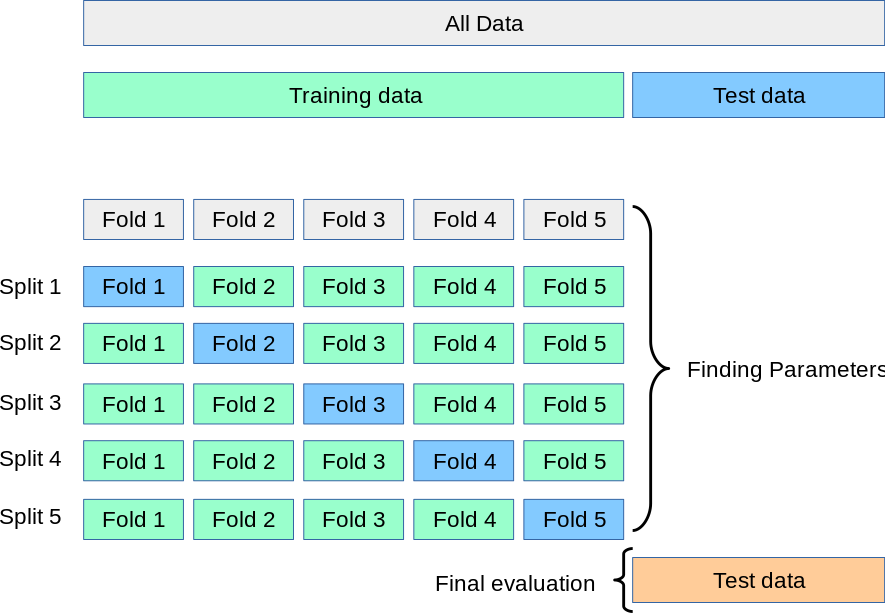

**1. Por qué se dice que “ayuda a evitar el sobreajuste”**

Ojo con la frase: la CV no impide que un modelo sobreajuste. Lo que hace es detectarlo, y así evita que elijas un modelo sobreajustado.

Un modelo sobreajustado memoriza el train: en el train le va bárbaro, y con datos nuevos le va mal.
Si evaluaras en el train, el modelo que memoriza parecería el mejor, y lo elegirías.
Con la CV, cada evaluación se hace con un fold que ese modelo no vio. El que memorizó queda en evidencia: en validación le va mal.
Entonces, al comparar modelos o hiperparámetros (como C y gamma), elegís el que generaliza, no el que memoriza.

Analogía: un alumno que memorizó las respuestas de la guía de ejercicios. Si lo evaluás con la misma guía, saca 10. Si lo evaluás con preguntas nuevas, se nota que no entendió. La CV es tomarle preguntas nuevas.

**2. La “suerte” de una sola partición**

Si en lugar de CV hacés una sola división del train (por ejemplo, 80% para entrenar y 20% para validar):

Esa división es al azar, y por azar puede salir un 20% de validación con casos fáciles, y el modelo parece mejor de lo que es.
O puede salir con casos difíciles, y parece peor.
Si comparás dos modelos con una sola división, uno puede ganar por suerte, no por ser mejor.

La CV reduce esa suerte: evalúa con 5 validaciones distintas y promedia. Una validación “fácil” y una “difícil” se compensan, y el promedio es más confiable. Además, podés ver cuánto varía el resultado entre folds: si varía mucho, el modelo es inestable.

Analogía: juzgar a un alumno por un solo examen (que pudo tocarle fácil) o por el promedio de 5 exámenes.

Resumen: los beneficios de la CV

Mide el rendimiento con datos no vistos, usando solo el train. Así detecta el sobreajuste y te deja elegir el modelo que generaliza.
Reduce la suerte de una sola partición, porque promedia varias.
Aprovecha todos los datos: cada fila sirve para entrenar y también para validar (una vez).

La validación cruzada es una técnica para estimar cómo rinde un modelo con datos que no vio, usando solo el conjunto de entrenamiento. Divide el train en k folds (grupos distintos de filas, con todas las columnas: features y target). En cada iteración entrena un modelo con k − 1 folds y lo valida con el fold restante, rotando cuál se usa para validar, de modo que cada fold valida una sola vez. Al final se promedian las métricas de validación. Esto tiene dos beneficios: (1) detecta el sobreajuste, porque un modelo que memoriza el entrenamiento rinde mal en validación, y así evita elegirlo; y (2) reduce el efecto de la suerte de una única partición aleatoria (por ejemplo, que la validación quede con casos especialmente fáciles), porque promedia varias validaciones distintas. Por eso se usa para comparar modelos y ajustar hiperparámetros, dejando el test final para una única evaluación al terminar.